# Stochastic subspace identification: modes of a noise-driven system

Harmonic inversion fits damped exponentials to a signal that *is* a sum
of damped exponentials: a free decay, a ring-down, an impulse response.
Many systems cannot be switched off or hit with a hammer, though. A bridge
vibrates in the wind and under traffic, a machine runs, a resonator is
shaken by thermal noise. What can be measured is the response *while the
system is driven* by an unknown, broadband excitation.

Such a signal is not a sum of damped exponentials: it never decays, and
every new kick of the excitation restarts every mode with a random phase.
**Stochastic subspace identification** (SSI) identifies the modes
(frequencies, damping, mode shapes) from such output-only data. This
notebook shows how it works and how to use `pyharminv.ssi`:

1. a model system driven by random forces,
2. why harmonic inversion of the raw signal fails, and why the
   correlation function rescues it,
3. covariance-driven SSI (`ssi_cov`) step by step,
4. the stabilization diagram,
5. mode shapes and the model spectrum,
6. data-driven SSI (`ssi_data`),
7. practical settings.

The companion notebook `06_choosing_an_identification_method.ipynb`
compares the methods and says when to use which.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.linalg import eigh

from pyharminv import (harminv, mac, output_correlation, random_vibration,
                       ssi, ssi_cov, ssi_data, ssi_stabilization)

plt.rcParams["figure.figsize"] = (9, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. A model system

Three masses in a chain, fixed to a wall at the left end, with light
Rayleigh damping $C = \alpha M + \beta K$:

```
wall —k1— m1 —k2— m2 —k3— m3
```

Every mass is pushed by its own independent white-noise force, and the
displacements of all three masses are measured, with 10 % measurement
noise on top. `random_vibration` simulates this exactly (the forces are
held constant over each sampling interval, and the system is discretised
exactly for such inputs). It also returns the true complex frequencies
$\omega_k = \Omega_k - i\Gamma_k/2$ in the convention of `harminv`, for
comparison.

In [2]:
M = np.eye(3)
k = np.array([1.0, 1.5, 2.0])
K = np.diag(k + np.append(k[1:], 0)) - np.diag(k[1:], 1) - np.diag(k[1:], -1)
C = 0.02 * M + 0.02 * K
dt = 0.3
N = 30_000

y, omega_true = random_vibration(M, C, K, dt, N, noise=0.1, rng=1)
t = dt * np.arange(N)
zeta_true = -omega_true.imag / np.abs(omega_true)
shapes_true = eigh(K, M)[1].T          # undamped modes = modes of Rayleigh damping
print("true omega:", omega_true)
print("true damping ratios:", zeta_true)

true omega: [0.4866-0.0124j 1.5262-0.0333j 2.3299-0.0643j]
true damping ratios: [0.0254 0.0218 0.0276]


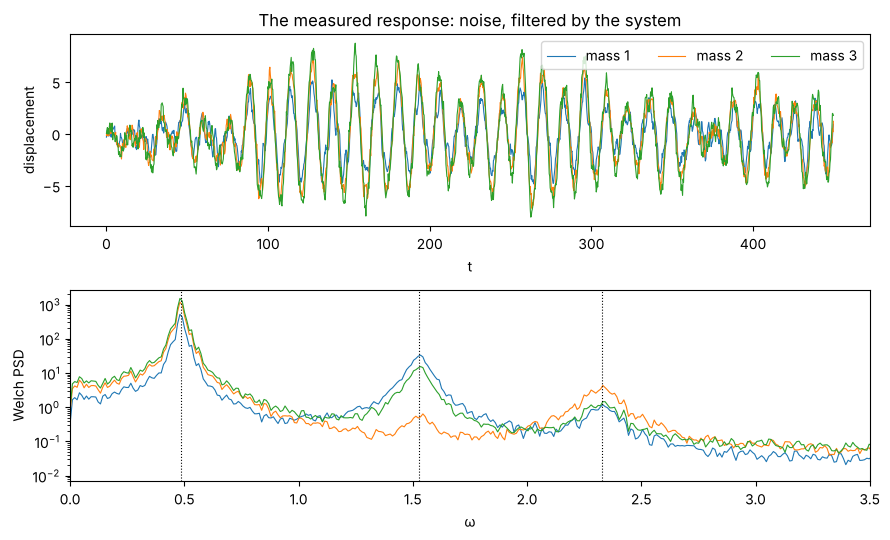

In [3]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.5))
for j in range(3):
    ax[0].plot(t[:1500], y[:1500, j], lw=0.8, label=f"mass {j + 1}")
ax[0].set_xlabel("t")
ax[0].set_ylabel("displacement")
ax[0].legend(loc="upper right", ncol=3)
ax[0].set_title("The measured response: noise, filtered by the system")
f, P = welch(y, fs=1 / dt, nperseg=2048, axis=0)
for j in range(3):
    ax[1].semilogy(2 * np.pi * f, P[:, j], lw=0.8)
for w in omega_true.real:
    ax[1].axvline(w, color="k", ls=":", lw=0.8)
ax[1].set_xlabel("ω")
ax[1].set_ylabel("Welch PSD")
ax[1].set_xlim(0, 3.5)
fig.tight_layout()

The time signal looks like noise. The spectrum shows three peaks at the
resonances (dotted), broadened by the averaging that Welch's method needs
to tame the noise of a random signal. Reading damping from such peaks
(half-power bandwidth) is biased by the window and the averaging.

## 2. Harmonic inversion of the raw signal, and of the correlation

Let us first try `harminv` on the raw response of mass 1.

In [4]:
raw = harminv(y[:4000, 0], dt, tol=1e-2)
print(len(raw), "modes; the strongest ones:")
print(raw[np.argsort(-raw.magnitude)[:6]])

102 modes; the strongest ones:
HarmInvResult with 6 modes (real signal)
    omega.real     omega.imag          Q         |d|    arg d     error
     0.4824381   -0.004837639      49.86       5.144  -2.1339    0.0013
     0.4485274   -0.005710511      39.27       2.298   0.3318    0.0004
     0.4864579  -0.0001815879       1339       2.238   0.3681   0.00025
      1.618872   -0.005544698        146       1.363   1.4732   0.00047
     0.5005036    -0.00268038      93.36       1.325   2.1140    0.0002
     0.4246767   -0.004930408      43.07       1.131   1.2356   0.00067


Garbage: hundreds of "modes", the strongest ones not at the resonances.
Harmonic inversion assumes that the signal is a deterministic sum of
exponentials, but here the excitation keeps injecting energy at random
times.

The way out is a classical observation (the *natural excitation
technique*, NExT): for a linear system driven by white noise, the
**output correlation function**

$$R_{ab}(\tau) = E[y_a(t + \tau)\, y_b(t)]$$

satisfies the same equations of motion as the free response, so for
$\tau > 0$ it is a sum of damped exponentials with the system's poles.
Measurement noise only contributes at $\tau = 0$.

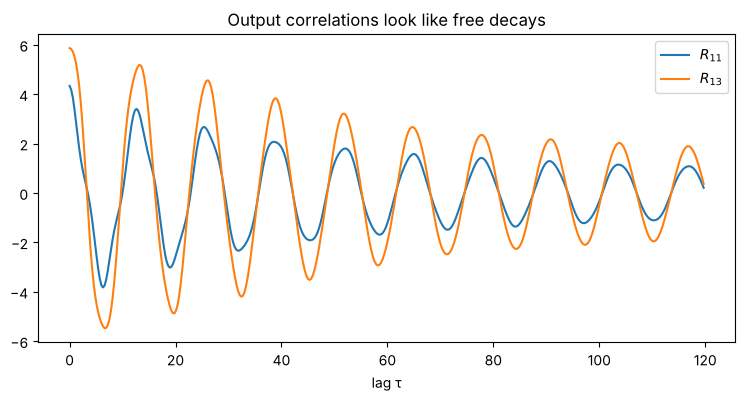

In [5]:
R = output_correlation(y, 400)          # R[k, a, b] at lag k dt
tau = dt * np.arange(400)
plt.plot(tau, R[:, 0, 0], label="$R_{11}$")
plt.plot(tau, R[:, 0, 2], label="$R_{13}$")
plt.xlabel("lag τ")
plt.legend()
plt.title("Output correlations look like free decays");

In [6]:
nexthi = harminv(R[1:, 0, 0], dt, tol=1e-2, t0=dt)
print(nexthi.select(min_magnitude=1e-3 * nexthi.magnitude.max()))
print("true:", omega_true)

HarmInvResult with 2 modes (real signal)
    omega.real     omega.imag          Q         |d|    arg d     error
     0.4850313    -0.01383542      17.53       3.804  -0.1249     5e-05
      1.529935    -0.03766083      20.31      0.5945  -0.4521   0.00039
true: [0.4866-0.0124j 1.5262-0.0333j 2.3299-0.0643j]


Harmonic inversion of the correlation function works. This is
essentially what covariance-driven SSI does, but SSI does it for all
channels at once, which brings in the mode shapes, separates modes that
are weak in one channel or close in frequency, and comes with a proper
stochastic model.

## 3. Covariance-driven SSI

SSI assumes a linear state-space model driven by white noise,

$$x_{k+1} = A x_k + w_k, \qquad y_k = C x_k + v_k,$$

with an unknown state $x_k$ of dimension $n$ (the **model order**, two per
oscillating mode). The correlations are then $R_k = C A^{k-1} G$ for
$k \geq 1$, with $G = E[x_{k+1} y_k^T]$. Stacking $R_1, \dots, R_{2i-1}$
in a block Toeplitz matrix

$$
T = \begin{pmatrix} R_i & R_{i-1} & \cdots & R_1\\
                    R_{i+1} & R_i & \cdots & R_2\\
                    \vdots & & & \vdots\\
                    R_{2i-1} & & \cdots & R_i \end{pmatrix}
  = \underbrace{\begin{pmatrix} C\\ CA\\ \vdots\\ CA^{i-1}\end{pmatrix}}_{O_i}
    \underbrace{\begin{pmatrix} A^{i-1}G & \cdots & G\end{pmatrix}}_{\Gamma_i}
$$

factors it into the observability and controllability matrices, so its
rank is $n$. A truncated SVD $T \approx U_n S_n V_n^T$ gives
$O_i = U_n S_n^{1/2}$; $C$ is its first block row and $A$ follows from
the shift structure $O_i[\text{rows }2\ldots] = O_i[\text{rows }1\ldots]\,A$.
The eigenvalues $\lambda_j$ of $A$ are the discrete poles,
$\lambda_j = e^{-i\omega_j\,\Delta t}$, and $C\psi_j$ (with $\psi_j$ the
eigenvectors) are the mode shapes.

The number of block rows $i$ sets the longest lag used, $2i\,\Delta t$.
The singular values show the order:

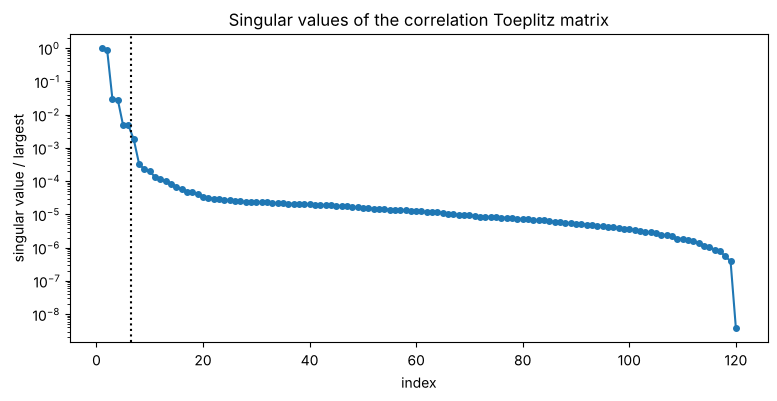

In [7]:
r = ssi_cov(y, dt, order=16, block_rows=40)
s = r.info["singular_values"]
plt.semilogy(np.arange(1, len(s) + 1), s / s[0], "o-", ms=4)
plt.axvline(6.5, color="k", ls=":")
plt.xlabel("index")
plt.ylabel("singular value / largest")
plt.title("Singular values of the correlation Toeplitz matrix");

Three modes, six singular values clearly above the floor. The floor is not
far below, though: with random data the correlations are only estimated,
and the weak third mode is not much stronger than the estimation noise.
It is therefore good practice to choose the order **larger** than needed
(here 16 instead of 6) and to remove the spurious poles afterwards.

`ssi_cov` returns an `SSIResult`, which is a `HarmInvResult` of the
correlation function: `omega`, `amplitude` (the coefficients of the
auto-correlation of a reference channel, channel 0 by default), `error`,
plus `mode_shape`, `residue` (coefficients of all correlations),
`damping_ratio` and more.

In [8]:
print(r)

SSIResult with 6 modes, order 16, 3 channel(s), method cov
    omega.real     omega.imag       zeta         |d|     error
     0.2166324    -0.07033743     0.3088     0.01106     0.086
     0.4859689    -0.01245042    0.02561       3.645   0.00023
     0.6924767     -0.1189334     0.1693     0.00907      0.16
      1.214143    -0.06968433     0.0573    0.004295       0.2
      1.527032    -0.03756303    0.02459      0.6036     0.003
       2.32562    -0.06886406     0.0296     0.03283   3.2e-05


Besides the three modes there are spurious poles that model the noise.
They differ in three ways:

* their `error` is large: it is the distance to the closest pole of an
  identification with order `order + 2`, and spurious poles move when the
  order changes, physical ones stay;
* their contribution to the correlation (`|d|`) is small;
* their damping is often unphysical (very large, or close to zero).

`select` filters on all of these, including bounds on the damping ratio:

In [9]:
modes = r.select(max_rel_error=0.01, max_damping=0.2)
modes = modes.select(min_magnitude=1e-3 * modes.magnitude.max())
print(modes)
print()
print("frequency error / %:", 100 * (modes.omega.real - omega_true.real) / omega_true.real)
print("damping error / %:  ", 100 * (modes.damping_ratio - zeta_true) / zeta_true)

SSIResult with 3 modes, order 16, 3 channel(s), method cov
    omega.real     omega.imag       zeta         |d|     error
     0.4859689    -0.01245042    0.02561       3.645   0.00023
      1.527032    -0.03756303    0.02459      0.6036     0.003
       2.32562    -0.06886406     0.0296     0.03283   3.2e-05

frequency error / %: [-0.135   0.0526 -0.1836]
damping error / %:   [ 0.7891 12.7189  7.2462]


Frequencies are accurate to a fraction of a per cent. Damping ratios
are much harder: their error is dominated by the *statistical* error of a
finite random record, not by the method, and shrinks only like
$1/\sqrt{T}$. Notebook 06 quantifies this.

## 4. The stabilization diagram

Choosing the order is the main practical decision in SSI. The standard
tool is the stabilization diagram: identify for many orders and plot the
poles. Physical poles stay put and line up vertically; noise poles
scatter. `ssi_stabilization` does this from a single SVD and flags poles
that are stable in frequency (1 %), damping (5 %) and mode shape
(MAC ≥ 0.98) compared to the next lower order.

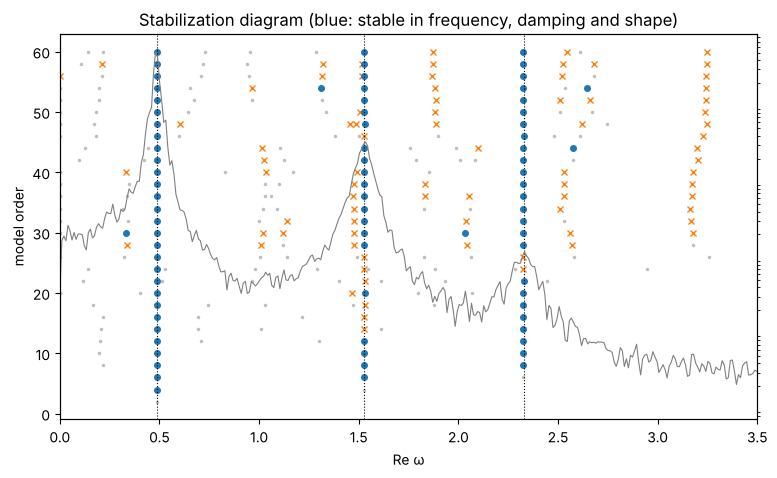

In [10]:
st = ssi_stabilization(y, dt, range(2, 61, 2), block_rows=40)
fig, ax = plt.subplots(figsize=(9, 5))
st.plot(ax)
ax2 = ax.twinx()
ax2.semilogy(2 * np.pi * f, P[:, 0], color="0.5", lw=0.8)
ax2.set_yticks([])
for w in omega_true.real:
    ax.axvline(w, color="k", ls=":", lw=0.8)
ax.set_xlim(0, 3.5)
ax.set_title("Stabilization diagram (blue: stable in frequency, damping and shape)");

Above order 6 all three modes are stable. Here and there a spurious
pole lands close to a physical one at a single order; it can split a mode
in two or pull its damping, which is why one should not rely on one
order alone. The stable poles over all orders can be collected directly:

In [11]:
order, w, z, _ = st.poles(stable_only=True)
for wk in omega_true:
    near = np.abs(w - wk) < 0.02 * abs(wk)
    print(f"true {wk.real:.4f}: stable at {near.sum():2d} orders, "
          f"Re ω = {np.median(w[near].real):.4f}, ζ = {np.median(z[near]):.4f} "
          f"(true {-wk.imag / abs(wk):.4f})")

true 0.4866: stable at 29 orders, Re ω = 0.4858, ζ = 0.0256 (true 0.0254)
true 1.5262: stable at 21 orders, Re ω = 1.5276, ζ = 0.0239 (true 0.0218)
true 2.3299: stable at 25 orders, Re ω = 2.3262, ζ = 0.0295 (true 0.0276)


## 5. Mode shapes and the model spectrum

With several channels, SSI also returns the mode shapes: how the masses
move relative to each other in each mode. The modal assurance criterion
(MAC, 1 for identical shapes) compares them with the true ones.

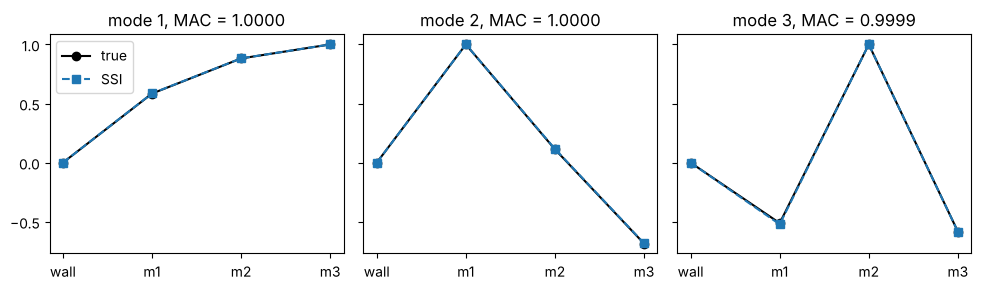

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for j, ax in enumerate(axs):
    est = modes.mode_shape[j]
    est = est * np.sign(est.real[np.argmax(abs(est))])
    tru = shapes_true[j] / shapes_true[j][np.argmax(abs(shapes_true[j]))]
    ax.plot([0, 1, 2, 3], np.r_[0, tru], "k-o", label="true")
    ax.plot([0, 1, 2, 3], np.r_[0, est.real], "C0--s", label="SSI")
    ax.set_title(f"mode {j + 1}, MAC = {mac(est, shapes_true[j])[0, 0]:.4f}")
    ax.set_xticks([0, 1, 2, 3], ["wall", "m1", "m2", "m3"])
axs[0].legend()
fig.tight_layout()

The identified model also predicts the correlation functions and their
spectra (`correlation`, `psd`). `psd` is the two-sided spectral density
per unit angular frequency, so the one-sided Welch estimate per Hz
corresponds to `2 * psd(2 π f)`. The model spectrum is smooth and has no
averaging bias, unlike the Welch estimate.

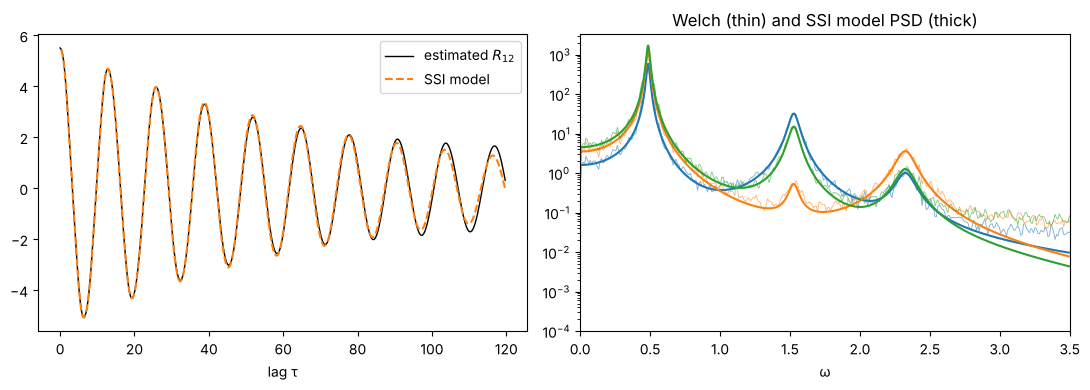

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tau, R[:, 0, 1], "k", lw=1, label="estimated $R_{12}$")
ax[0].plot(tau[1:], modes.correlation(tau[1:])[:, 0, 1], "C1--", label="SSI model")
ax[0].set_xlabel("lag τ")
ax[0].legend()
wgrid = np.linspace(0.01, 3.5, 2000)
S = modes.psd(wgrid, full=True)
for j in range(3):
    ax[1].semilogy(2 * np.pi * f, P[:, j], color=f"C{j}", lw=0.6, alpha=0.6)
    ax[1].semilogy(wgrid, 2 * S[:, j, j].real, color=f"C{j}", lw=1.5)
ax[1].set_xlim(0, 3.5)
ax[1].set_ylim(1e-4, None)
ax[1].set_xlabel("ω")
ax[1].set_title("Welch (thin) and SSI model PSD (thick)")
fig.tight_layout()

At high frequencies the Welch estimates level off at the measurement
noise, which the model of the modes leaves out.

## 6. Data-driven SSI

Covariance-driven SSI first condenses the data into correlation
estimates. Data-driven SSI works on the data directly. It builds the
block Hankel matrix of the outputs and splits it into "past" and "future"
rows,

$$
\begin{pmatrix} Y_p \\ Y_f \end{pmatrix} =
\frac{1}{\sqrt{j}}
\begin{pmatrix} y_0 & y_1 & \cdots & y_{j-1}\\
                \vdots & & & \vdots\\
                y_{i-1} & y_i & \cdots & y_{i+j-2}\\ \hline
                y_i & y_{i+1} & \cdots & y_{i+j-1}\\
                \vdots & & & \vdots\\
                y_{2i-1} & y_{2i} & \cdots & y_{2i+j-2}
\end{pmatrix}.
$$

The orthogonal projection of the future onto the past, $Y_f / Y_p$, is
the best linear prediction of the future from the past. For the
stochastic model it factors as $O_i \hat X_i$, where $\hat X_i$ are the
states of a bank of Kalman filters. A truncated SVD of the projection
gives $O_i$ and $\hat X_i$, the same is done one step later, and
$(A, C)$ solve the least-squares problem
$\begin{pmatrix}\hat X_{i+1}\\ Y_{i|i}\end{pmatrix} = \begin{pmatrix} A \\ C\end{pmatrix} \hat X_i$.
The projection is computed from an LQ (QR) factorisation of the Hankel
matrix, which never forms products of the data and is numerically
robust. The interface is the same:

In [14]:
rd = ssi_data(y, dt, order=16, block_rows=40)
modes_d = rd.select(max_rel_error=0.01, max_damping=0.2)
modes_d = modes_d.select(min_magnitude=1e-3 * modes_d.magnitude.max())
print(modes_d)
print()
print("frequency error / %:", 100 * (modes_d.omega.real - omega_true.real) / omega_true.real)
print("damping error / %:  ", 100 * (modes_d.damping_ratio - zeta_true) / zeta_true)
print("MAC with SSI-Cov shapes:", np.diag(mac(modes_d.mode_shape, modes.mode_shape)))

SSIResult with 3 modes, order 16, 3 channel(s), method data
    omega.real     omega.imag       zeta         |d|     error
     0.4857827    -0.01242909    0.02558       3.651    0.0003
      1.530648    -0.03744027    0.02445      0.5988    0.0018
      2.325379    -0.07040537    0.03026     0.03338   0.00057

frequency error / %: [-0.1733  0.2895 -0.1939]
damping error / %:   [ 0.6551 12.0856  9.6558]
MAC with SSI-Cov shapes: [1.     0.9999 1.    ]


Both variants agree within their statistical errors. When to prefer which
is the topic of notebook 06. In short: SSI-Cov is cheaper, in particular
for long records, and the correlations can be averaged over several
records; SSI-Data tends to be a little more accurate for short records
and is numerically more robust.

## 7. Practical settings

* **Remove the mean** (and drifts) first, e.g. with
  `pyharminv.remove_mean` or `detrend`: an offset looks like a mode at
  zero frequency.
* **Block rows** `i`: the lags used reach $2i\,\Delta t$. It should cover
  at least about one period of the slowest mode of interest, and
  `i * n_channels` must exceed the order. More rows reduce the bias but
  increase the variance and the cost. 20–100 rows are typical.
* **Order**: two per mode, plus margin for noise and for a coloured
  excitation. Overestimate, then `select`; check with a stabilization
  diagram.
* **Sampling**: much faster sampling than needed makes the poles crowd
  near $\lambda = 1$ and demands many block rows; low-pass filter and
  decimate first.
* **Excitation**: SSI assumes broadband excitation. Harmonic components
  (rotating machines) appear as poles with almost zero damping; the
  colour of the excitation adds extra poles. Notebook 06 shows both.
* **Record length**: the statistical error of the damping ratio decreases
  only like $1/\sqrt{T}$. Records of several hundred to a thousand
  periods of the slowest mode are common in operational modal analysis.